# Gradient-Based Learning
## Linear Regression and a One-Hidden-Layer Neural Network

This notebook derives the gradients used in the code and implements both models from scratch with NumPy. Training uses manual full-batch Gradient Descent; Matplotlib is used for the required graphs.

## 1. Imports and reproducibility

The dataset and network parameters use independent, fixed random-number-generator seeds so that repeated executions produce the same values.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=8, suppress=True)
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
DATASET_SEED = 42
PARAMETER_SEED = 7

## 2. Dataset generation

The dataset contains 100 evenly spaced scalar inputs from -2 to 2. Targets follow $Y=X^2+\epsilon$, where $\epsilon$ is Gaussian noise with standard deviation 0.15. Both arrays have shape $(100,1)$ and use `float64`.

In [2]:
rng = np.random.default_rng(DATASET_SEED)
X = np.linspace(-2.0, 2.0, 100, dtype=np.float64).reshape(-1, 1)
noise = rng.normal(0.0, 0.15, size=(100, 1))
Y = X ** 2 + noise

assert X.shape == (100, 1) and Y.shape == (100, 1)
assert X.dtype == np.float64 and Y.dtype == np.float64
print(f"X shape: {X.shape}, Y shape: {Y.shape}")
print(f"X dtype: {X.dtype}, Y dtype: {Y.dtype}")

X shape: (100, 1), Y shape: (100, 1)
X dtype: float64, Y dtype: float64


## 3. Dataset and models

The target is nonlinear: $Y=X^2+\epsilon$. Linear Regression learns one straight line, while the $1\rightarrow8\rightarrow1$ ReLU network can form a piecewise-linear approximation. Every update uses all 100 samples.

## 4. Linear Regression gradient derivation

For sample $i$,

$$\hat{y}_i=wx_i+b, \qquad L_i=(\hat{y}_i-y_i)^2.$$

The local derivatives are

$$\frac{\partial L_i}{\partial \hat{y}_i}=2(\hat{y}_i-y_i),\qquad
\frac{\partial \hat{y}_i}{\partial w}=x_i,\qquad
\frac{\partial \hat{y}_i}{\partial b}=1.$$

Applying the chain rule and averaging over $n$ samples gives

$$\frac{\partial L}{\partial w}=\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)x_i
=\frac{2}{n}X^T(\hat{Y}-Y),$$

$$\frac{\partial L}{\partial b}=\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i).$$

Gradient descent then uses $w\leftarrow w-\eta\,\partial L/\partial w$ and $b\leftarrow b-\eta\,\partial L/\partial b$.

## 5. Linear Regression implementation

The functions below implement prediction, MSE, the two analytical gradients, and 1,000 full-batch updates. Loss history begins at iteration 0, before any update.

In [3]:
def linear_predict(X_values, w, b):
    return X_values @ w + b


def mean_squared_error(y_hat, y_true):
    return float(np.mean((y_hat - y_true) ** 2))


def linear_gradients(X_values, y_true, y_hat):
    n = X_values.shape[0]
    error = y_hat - y_true
    dw = (2.0 / n) * (X_values.T @ error)
    db = (2.0 / n) * np.sum(error, axis=0, keepdims=True)
    return dw, db


def train_linear_regression(X_values, y_true, learning_rate=0.05, iterations=1000):
    w = np.zeros((1, 1), dtype=np.float64)
    b = np.zeros((1, 1), dtype=np.float64)
    loss_history = [mean_squared_error(linear_predict(X_values, w, b), y_true)]

    for _ in range(iterations):
        y_hat = linear_predict(X_values, w, b)
        dw, db = linear_gradients(X_values, y_true, y_hat)
        w = w - learning_rate * dw
        b = b - learning_rate * db
        loss_history.append(mean_squared_error(linear_predict(X_values, w, b), y_true))

    return w, b, np.asarray(loss_history, dtype=np.float64)


assert linear_gradients(X, Y, np.zeros_like(Y))[0].shape == (1, 1)
assert linear_gradients(X, Y, np.zeros_like(Y))[1].shape == (1, 1)

## 6. Linear Regression execution and actual results

In [4]:
LINEAR_LEARNING_RATE = 0.05
LINEAR_ITERATIONS = 1000
linear_w, linear_b, linear_losses = train_linear_regression(
    X, Y, learning_rate=LINEAR_LEARNING_RATE, iterations=LINEAR_ITERATIONS
)
linear_predictions = linear_predict(X, linear_w, linear_b)

assert linear_w.shape == (1, 1) and linear_b.shape == (1, 1)
assert linear_losses.shape == (LINEAR_ITERATIONS + 1,)
print(f"Iteration 0 (initial) loss: {linear_losses[0]:.12f}")
print(f"Iteration {LINEAR_ITERATIONS} (final) loss: {linear_losses[-1]:.12f}")
print(f"Learned weight: {linear_w.item():.12f}")
print(f"Learned bias: {linear_b.item():.12f}")

Iteration 0 (initial) loss: 3.267617878211
Iteration 1000 (final) loss: 1.437405676723
Learned weight: -0.015732313764
Learned bias: 1.352728918547


## 7. Linear Regression graphs

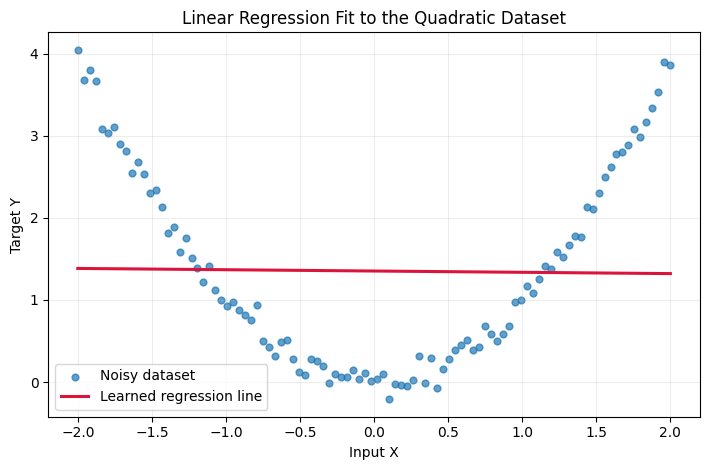

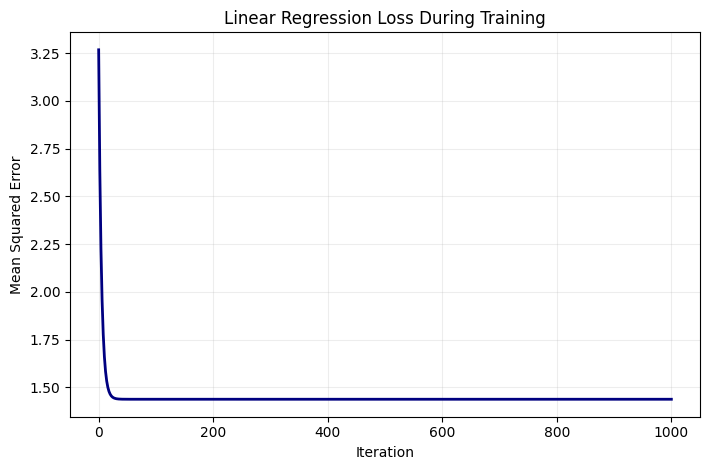

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.scatter(X[:, 0], Y[:, 0], s=24, alpha=0.70, label="Noisy dataset")
ax.plot(X[:, 0], linear_predictions[:, 0], color="crimson", linewidth=2.2, label="Learned regression line")
ax.set_title("Linear Regression Fit to the Quadratic Dataset")
ax.set_xlabel("Input X")
ax.set_ylabel("Target Y")
ax.legend()
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_regression_fit.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.plot(np.arange(linear_losses.size), linear_losses, color="navy", linewidth=2)
ax.set_title("Linear Regression Loss During Training")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean Squared Error")
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linear_regression_loss.png", dpi=160)
plt.show()

## 8. Neural-network architecture and forward pass

The network has one input, eight ReLU hidden units, and one linear output:

$$Z_1=XW_1+b_1,\qquad A_1=\operatorname{ReLU}(Z_1),\qquad \hat{Y}=A_1W_2+b_2.$$

The parameter shapes are $W_1:(1,8)$, $b_1:(1,8)$, $W_2:(8,1)$, and $b_2:(1,1)$.

## 9. Neural-network backward pass

For Mean Squared Error,

$$d\hat{Y}=\frac{2}{n}(\hat{Y}-Y).$$

For output-weight component $j$,

$$\frac{\partial L}{\partial W_{2,j}}
=\sum_i\frac{\partial L}{\partial\hat{y}_i}\frac{\partial\hat{y}_i}{\partial W_{2,j}}
=\sum_i d\hat{y}_i A_{1,ij},$$

so $dW_2=A_1^T d\hat{Y}$. Propagating to the hidden layer gives

$$dA_1=d\hat{Y}W_2^T,\qquad dZ_1=dA_1\odot\operatorname{ReLU}'(Z_1).$$

For first-layer weight component $j$,

$$\frac{\partial L}{\partial W_{1,j}}
=\sum_i\frac{\partial L}{\partial Z_{1,ij}}\frac{\partial Z_{1,ij}}{\partial W_{1,j}}
=\sum_i dZ_{1,ij}x_i,$$

so $dW_1=X^T dZ_1$. The complete matrix gradients implemented below are

$$dW_2=A_1^T d\hat{Y},\qquad db_2=\sum_i d\hat{Y}_i,$$
$$dA_1=d\hat{Y}W_2^T,\qquad dZ_1=dA_1\odot\operatorname{ReLU}'(Z_1),$$
$$dW_1=X^T dZ_1,\qquad db_1=\sum_i dZ_{1,i}.$$

The code uses $\operatorname{ReLU}'(z)=0$ at $z=0$.

## 10. Neural-network implementation

In [6]:
def relu(z):
    return np.maximum(0.0, z)


def relu_derivative(z):
    return (z > 0).astype(np.float64)


def initialize_parameters(input_size=1, hidden_size=8, output_size=1, seed=7, scale=0.5):
    parameter_rng = np.random.default_rng(seed)
    return {
        "W1": parameter_rng.normal(0.0, scale, size=(input_size, hidden_size)).astype(np.float64),
        "b1": np.zeros((1, hidden_size), dtype=np.float64),
        "W2": parameter_rng.normal(0.0, scale, size=(hidden_size, output_size)).astype(np.float64),
        "b2": np.zeros((1, output_size), dtype=np.float64),
    }


def neural_network_forward(X_values, parameters):
    Z1 = X_values @ parameters["W1"] + parameters["b1"]
    A1 = relu(Z1)
    y_hat = A1 @ parameters["W2"] + parameters["b2"]
    cache = {"Z1": Z1, "A1": A1, "Y_hat": y_hat}
    return y_hat, cache


def neural_network_backward(X_values, y_true, parameters, cache):
    n = X_values.shape[0]
    dY_hat = (2.0 / n) * (cache["Y_hat"] - y_true)
    dW2 = cache["A1"].T @ dY_hat
    db2 = np.sum(dY_hat, axis=0, keepdims=True)
    dA1 = dY_hat @ parameters["W2"].T
    dZ1 = dA1 * relu_derivative(cache["Z1"])
    dW1 = X_values.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


def update_parameters(parameters, gradients, learning_rate):
    return {
        name: parameters[name] - learning_rate * gradients[name]
        for name in ("W1", "b1", "W2", "b2")
    }


def neural_network_predict(X_values, parameters):
    return neural_network_forward(X_values, parameters)[0]


def train_neural_network(X_values, y_true, initial_parameters, learning_rate, iterations=5000):
    parameters = {name: value.copy() for name, value in initial_parameters.items()}
    initial_prediction, _ = neural_network_forward(X_values, parameters)
    loss_history = [mean_squared_error(initial_prediction, y_true)]
    finite = bool(np.isfinite(loss_history[0]) and all(np.all(np.isfinite(v)) for v in parameters.values()))

    for _ in range(iterations):
        y_hat, cache = neural_network_forward(X_values, parameters)
        gradients = neural_network_backward(X_values, y_true, parameters, cache)
        candidate_parameters = update_parameters(parameters, gradients, learning_rate)
        candidate_prediction = neural_network_predict(X_values, candidate_parameters)
        candidate_loss = mean_squared_error(candidate_prediction, y_true)

        candidate_is_finite = bool(
            np.isfinite(candidate_loss)
            and all(np.all(np.isfinite(v)) for v in candidate_parameters.values())
        )
        if not candidate_is_finite:
            finite = False
            break

        parameters = candidate_parameters
        loss_history.append(candidate_loss)

    return parameters, np.asarray(loss_history, dtype=np.float64), finite


original_parameters = initialize_parameters(seed=PARAMETER_SEED)
assert original_parameters["W1"].shape == (1, 8)
assert original_parameters["b1"].shape == (1, 8)
assert original_parameters["W2"].shape == (8, 1)
assert original_parameters["b2"].shape == (1, 1)
print({name: value.shape for name, value in original_parameters.items()})

{'W1': (1, 8), 'b1': (1, 8), 'W2': (8, 1), 'b2': (1, 1)}


## 11. Learning-rate experiment

The network is trained separately with learning rates 0.001, 0.01, and 0.1. Each run starts from a copy of the same parameters and records loss from iteration 0 through 5,000 updates.

In [7]:
NN_ITERATIONS = 5000
LEARNING_RATES = (0.001, 0.01, 0.1)
nn_runs = {}

for learning_rate in LEARNING_RATES:
    trained_parameters, loss_history, finite = train_neural_network(
        X,
        Y,
        original_parameters,
        learning_rate=learning_rate,
        iterations=NN_ITERATIONS,
    )
    nn_runs[learning_rate] = {
        "parameters": trained_parameters,
        "loss_history": loss_history,
        "finite": finite,
    }

initial_losses = np.asarray([nn_runs[lr]["loss_history"][0] for lr in LEARNING_RATES])
assert np.array_equal(initial_losses, np.repeat(initial_losses[0], len(LEARNING_RATES)))
print("Initial losses are identical:", initial_losses)

Initial losses are identical: [3.14090706 3.14090706 3.14090706]


## 12. Learning-rate results

The following cell selects the finite run with the lowest final MSE and labels the observed convergence speeds. The labels are: 0.001 stable but slow, 0.01 stable and faster, and 0.1 stable and fastest.

In [8]:
finite_rates = [lr for lr in LEARNING_RATES if nn_runs[lr]["finite"]]
if not finite_rates:
    raise RuntimeError("All neural-network learning-rate runs became non-finite.")

selected_learning_rate = min(
    finite_rates, key=lambda lr: nn_runs[lr]["loss_history"][-1]
)

stable_rates = [
    lr
    for lr in finite_rates
    if nn_runs[lr]["loss_history"][-1] <= nn_runs[lr]["loss_history"][0]
]
stable_rates_by_final_loss = sorted(
    stable_rates, key=lambda lr: nn_runs[lr]["loss_history"][-1]
)
stable_rate_rank = {lr: rank for rank, lr in enumerate(stable_rates_by_final_loss)}

for learning_rate in LEARNING_RATES:
    run = nn_runs[learning_rate]
    losses = run["loss_history"]
    if not run["finite"]:
        behavior = "diverged"
    elif losses[-1] > losses[0]:
        behavior = "unstable"
    elif stable_rate_rank[learning_rate] == 0:
        behavior = "stable and fastest"
    elif stable_rate_rank[learning_rate] == 1:
        behavior = "stable and faster"
    else:
        behavior = "stable but slow"
    run["behavior"] = behavior
    print(
        f"lr={learning_rate:g}: initial={losses[0]:.12f}, "
        f"final={losses[-1]:.12f}, finite={run['finite']}, "
        f"recorded_updates={losses.size - 1}, behavior={behavior}"
    )

print(f"Selected learning rate: {selected_learning_rate:g} (lowest finite final MSE among tested settings)")

lr=0.001: initial=3.140907059469, final=0.085072237697, finite=True, recorded_updates=5000, behavior=stable but slow
lr=0.01: initial=3.140907059469, final=0.023692447571, finite=True, recorded_updates=5000, behavior=stable and faster
lr=0.1: initial=3.140907059469, final=0.013474010362, finite=True, recorded_updates=5000, behavior=stable and fastest
Selected learning rate: 0.1 (lowest finite final MSE among tested settings)


## 13. Neural-network graphs

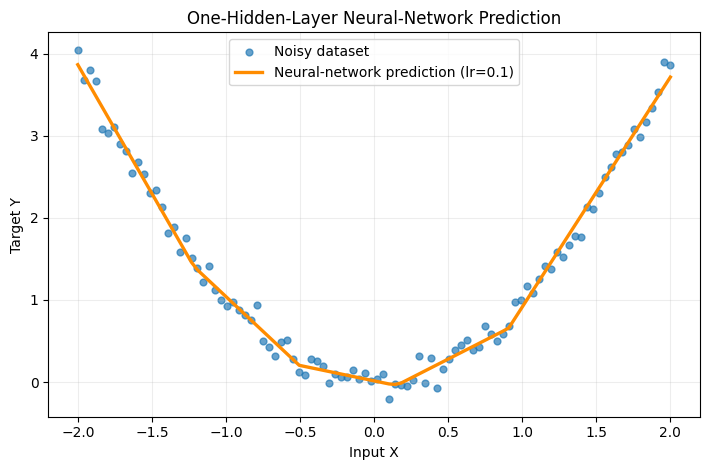

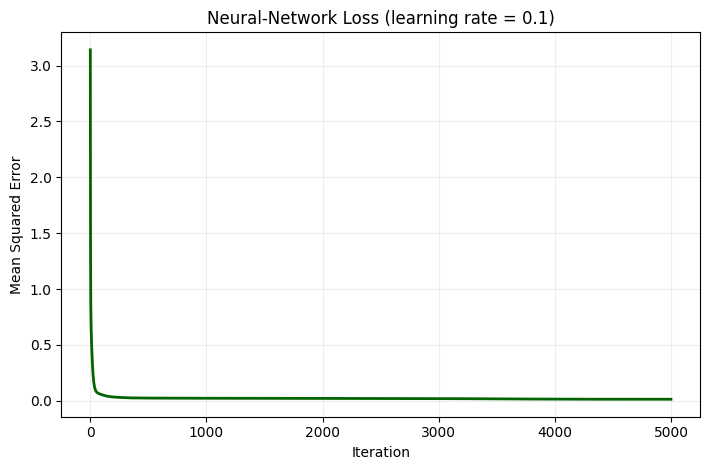

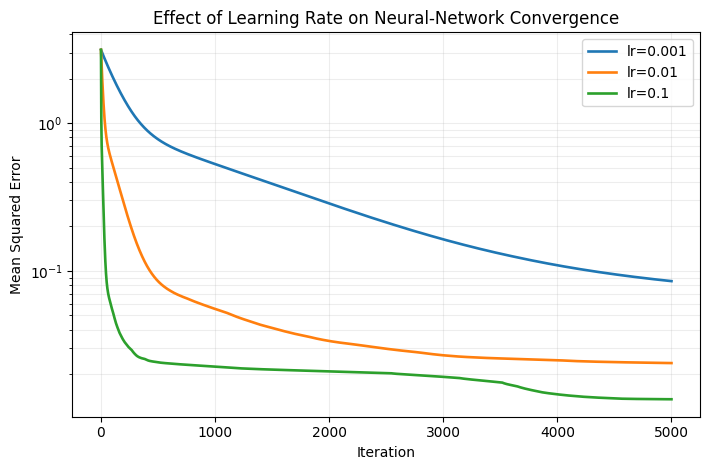

Learning-rate comparison uses logarithmic y-axis: True


In [9]:
selected_run = nn_runs[selected_learning_rate]
sort_order = np.argsort(X[:, 0])
sorted_X = X[sort_order]
selected_predictions = neural_network_predict(sorted_X, selected_run["parameters"])

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.scatter(X[:, 0], Y[:, 0], s=24, alpha=0.68, label="Noisy dataset")
ax.plot(
    sorted_X[:, 0],
    selected_predictions[:, 0],
    color="darkorange",
    linewidth=2.4,
    label=f"Neural-network prediction (lr={selected_learning_rate:g})",
)
ax.set_title("One-Hidden-Layer Neural-Network Prediction")
ax.set_xlabel("Input X")
ax.set_ylabel("Target Y")
ax.legend()
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "neural_network_prediction.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
selected_losses = selected_run["loss_history"]
ax.plot(np.arange(selected_losses.size), selected_losses, color="darkgreen", linewidth=2)
ax.set_title(f"Neural-Network Loss (learning rate = {selected_learning_rate:g})")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean Squared Error")
ax.grid(alpha=0.22)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "neural_network_loss.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
positive_losses = []
for learning_rate in LEARNING_RATES:
    losses = nn_runs[learning_rate]["loss_history"]
    positive_losses.extend(losses[losses > 0].tolist())
    ax.plot(np.arange(losses.size), losses, linewidth=1.9, label=f"lr={learning_rate:g}")

comparison_uses_log_scale = max(positive_losses) / min(positive_losses) >= 50.0
if comparison_uses_log_scale:
    ax.set_yscale("log")
ax.set_title("Effect of Learning Rate on Neural-Network Convergence")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean Squared Error")
ax.legend()
ax.grid(alpha=0.22, which="both")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_rate_comparison.png", dpi=160)
plt.show()
print("Learning-rate comparison uses logarithmic y-axis:", comparison_uses_log_scale)

## 14. Results and observations

The linear model converges to a nearly horizontal line and cannot represent the quadratic target. All three neural-network runs reduce the loss, and learning rate 0.1 has the lowest final MSE among the tested settings. The next cell saves the executed values to `results.json`.

In [10]:
results = {
    "dataset": {
        "samples": int(X.shape[0]),
        "x_min": float(X.min()),
        "x_max": float(X.max()),
        "noise_std": 0.15,
        "dataset_seed": DATASET_SEED,
        "x_shape": list(X.shape),
        "y_shape": list(Y.shape),
    },
    "linear_regression": {
        "learning_rate": LINEAR_LEARNING_RATE,
        "iterations": LINEAR_ITERATIONS,
        "initial_loss": float(linear_losses[0]),
        "final_loss": float(linear_losses[-1]),
        "weight": float(linear_w.item()),
        "bias": float(linear_b.item()),
    },
    "neural_network": {
        "hidden_neurons": 8,
        "parameter_seed": PARAMETER_SEED,
        "iterations": NN_ITERATIONS,
        "learning_rates": {
            f"{learning_rate:g}": {
                "initial_loss": float(nn_runs[learning_rate]["loss_history"][0]),
                "final_loss": float(nn_runs[learning_rate]["loss_history"][-1]),
                "finite": bool(nn_runs[learning_rate]["finite"]),
                "behavior": nn_runs[learning_rate]["behavior"],
                "recorded_updates": int(nn_runs[learning_rate]["loss_history"].size - 1),
            }
            for learning_rate in LEARNING_RATES
        },
        "selected_learning_rate": float(selected_learning_rate),
    },
}

with Path("results.json").open("w", encoding="utf-8") as results_file:
    json.dump(results, results_file, indent=2)
    results_file.write("\n")

print(json.dumps(results, indent=2))

{
  "dataset": {
    "samples": 100,
    "x_min": -2.0,
    "x_max": 2.0,
    "noise_std": 0.15,
    "dataset_seed": 42,
    "x_shape": [
      100,
      1
    ],
    "y_shape": [
      100,
      1
    ]
  },
  "linear_regression": {
    "learning_rate": 0.05,
    "iterations": 1000,
    "initial_loss": 3.267617878210513,
    "final_loss": 1.4374056767225096,
    "weight": -0.015732313763896316,
    "bias": 1.3527289185467808
  },
  "neural_network": {
    "hidden_neurons": 8,
    "parameter_seed": 7,
    "iterations": 5000,
    "learning_rates": {
      "0.001": {
        "initial_loss": 3.1409070594694795,
        "final_loss": 0.0850722376969346,
        "finite": true,
        "behavior": "stable but slow",
        "recorded_updates": 5000
      },
      "0.01": {
        "initial_loss": 3.1409070594694795,
        "final_loss": 0.023692447570899087,
        "finite": true,
        "behavior": "stable and faster",
        "recorded_updates": 5000
      },
      "0.1": {
        "